<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# <center> Проект: Анализ резюме из HeadHunter
   

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [2]:
# Читаем только заголовок файла (0 строк данных), чтобы проверить разделитель столбцов
pd.read_csv('dst-3.0_16_1_hh_database.csv', nrows=0)

,Пол,возраст;ЗП;Ищет работу на должность:;Город,переезд,командировки;Занятость;График;Опыт работы;Последнее/нынешнее место работы;Последняя/нынешняя должность;Образование и ВУЗ;Обновление резюме;Авто


In [3]:
# Читаем файл целиком
hh_data = pd.read_csv('dst-3.0_16_1_hh_database.csv', sep=';')

hh_data.shape

(44744, 12)

2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [4]:
display(hh_data.head())
display(hh_data.tail())

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
0,"Мужчина , 39 лет , родился 27 ноября 1979",29000 руб.,Системный администратор,"Советск (Калининградская область) , не готов к...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, ва...",Опыт работы 16 лет 10 месяцев Август 2010 — п...,"МАОУ ""СОШ № 1 г.Немана""",Системный администратор,Неоконченное высшее образование 2000 Балтийск...,16.04.2019 15:59,Имеется собственный автомобиль
1,"Мужчина , 60 лет , родился 20 марта 1959",40000 руб.,Технический писатель,"Королев , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, уд...",Опыт работы 19 лет 5 месяцев Январь 2000 — по...,Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель",Высшее образование 1981 Военно-космическая ак...,12.04.2019 08:42,Не указано
2,"Женщина , 36 лет , родилась 12 августа 1982",20000 руб.,Оператор,"Тверь , не готова к переезду , не готова к ком...",полная занятость,полный день,Опыт работы 10 лет 3 месяца Октябрь 2004 — Де...,ПАО Сбербанк,Кассир-операционист,Среднее специальное образование 2002 Профессио...,16.04.2019 08:35,Не указано
3,"Мужчина , 38 лет , родился 25 июня 1980",100000 руб.,Веб-разработчик (HTML / CSS / JS / PHP / базы ...,"Саратов , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, удаленная работа",Опыт работы 18 лет 9 месяцев Август 2017 — Ап...,OpenSoft,Инженер-программист,Высшее образование 2002 Саратовский государст...,08.04.2019 14:23,Не указано
4,"Женщина , 26 лет , родилась 3 марта 1993",140000 руб.,Региональный менеджер по продажам,"Москва , не готова к переезду , готова к коман...",полная занятость,полный день,Опыт работы 5 лет 7 месяцев Региональный мене...,Мармелад,Менеджер по продажам,Высшее образование 2015 Кгу Психологии и педаг...,22.04.2019 10:32,Не указано


,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
44739,"Мужчина , 30 лет , родился 17 января 1989",50000 руб.,"Финансист, аналитик, экономист, бухгалтер, мен...","Тверь , готов к переезду (Москва, Химки) , гот...",полная занятость,"полный день, удаленная работа","Опыт работы 7 лет 7 месяцев Финансист, аналит...","ООО ""IAS"" (независимый участник объединения Ru...",Руководитель субгруппы,Высшее образование 2015 Московский гуманитарн...,22.04.2019 12:32,Не указано
44740,"Мужчина , 27 лет , родился 5 марта 1992",39000 руб.,"Системный администратор, IT-специалист","Липецк , готов к переезду , готов к командировкам","проектная работа, частичная занятость, полная ...","удаленная работа, гибкий график, полный день, ...","Опыт работы 7 лет Системный администратор, IT...",ИП Пестрецов,Предприниматель,Высшее образование (Бакалавр) 2016 Воронежски...,22.04.2019 13:11,Не указано
44741,"Женщина , 48 лет , родилась 26 декабря 1970",40000 руб.,"Аналитик данных, Математик","Челябинск , готова к переезду , готова к редки...",полная занятость,"полный день, удаленная работа",Опыт работы 21 год 5 месяцев Январь 1998 — по...,"ОАО «ЧМК», Исследовательско-Технологический Це...",Начальник группы аналитики,Высшее образование 2000 Южно-Уральский госуда...,09.04.2019 05:07,Не указано
44742,"Мужчина , 24 года , родился 6 октября 1994",20000 руб.,Контент-менеджер,"Тамбов , не готов к переезду , не готов к кома...","частичная занятость, полная занятость",удаленная работа,Опыт работы 3 года 10 месяцев Контент-менедже...,IQ-Maxima,Менеджер проектов,Высшее образование 2015 Тамбовский государств...,26.04.2019 14:25,Имеется собственный автомобиль
44743,"Мужчина , 38 лет , родился 25 апреля 1980",120000 руб.,Руководитель проекта,"Москва , не готов к переезду , не готов к кома...",полная занятость,полный день,Опыт работы 15 лет 10 месяцев Руководитель пр...,ПАО ГК ТНС энерго,Руководитель отдела технической поддержки,Высшее образование 1997 Южно-Российский госуд...,05.07.2018 20:15,Не указано


3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

4. Обратите внимание на информацию о числе непустых значений.

In [5]:
hh_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   Пол, возраст                     44744 non-null  str  
 1   ЗП                               44744 non-null  str  
 2   Ищет работу на должность:        44744 non-null  str  
 3   Город, переезд, командировки     44744 non-null  str  
 4   Занятость                        44744 non-null  str  
 5   График                           44744 non-null  str  
 6   Опыт работы                      44576 non-null  str  
 7   Последнее/нынешнее место работы  44743 non-null  str  
 8   Последняя/нынешняя должность     44742 non-null  str  
 9   Образование и ВУЗ                44744 non-null  str  
 10  Обновление резюме                44744 non-null  str  
 11  Авто                             44744 non-null  str  
dtypes: str(12)
memory usage: 4.1 MB


5. Выведите основную статистическую информацию о столбцах.


In [6]:
hh_data.describe(include='all')

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
count,44744,44744,44744,44744,44744,44744,44576,44743,44742,44744,44744,44744
unique,16003,690,14929,10063,38,47,44413,30214,16927,40148,18838,2
top,"Мужчина , 32 года , родился 17 сентября 1986",50000 руб.,Системный администратор,"Москва , не готов к переезду , не готов к кома...",полная занятость,полный день,Опыт работы 10 лет 8 месяцев Апрель 2018 — по...,Индивидуальное предпринимательство / частная п...,Системный администратор,Высшее образование 2014 Московский технически...,07.05.2019 09:50,Не указано
freq,18,4064,3099,1261,30026,22727,3,935,2062,4,25,32268


# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [7]:
# Выделим уровень образования запишем в новый столбец
hh_data['Образование'] = hh_data['Образование и ВУЗ'].apply(
    lambda x: 'высшее' if x.startswith('Высшее') else
    'неоконченное высшее' if x.startswith('Неоконченное высшее') else
    'среднее специальное' if x.startswith('Среднее специальное') else
    'среднее'
)

hh_data['Образование'].unique()

<StringArray>
['неоконченное высшее', 'высшее', 'среднее специальное', 'среднее']
Length: 4, dtype: str

In [8]:
# Удалим исходный столбец
hh_data = hh_data.drop('Образование и ВУЗ', axis=1)

2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '. 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [9]:
# Извлечем пол соискателя
hh_data['Пол'] = hh_data['Пол, возраст'].apply(
    lambda x: 'М' if x.split(',')[0].strip() == 'Мужчина' else 'Ж'
)

# Извлечем возраст
hh_data['Возраст'] = hh_data['Пол, возраст'].apply(
    lambda x: int(x.split(',')[1].strip().split()[0])
)

# Проверим уникальные значения 
hh_data['Пол'].unique(), hh_data['Возраст'].dtype

(<StringArray>
 ['М', 'Ж']
 Length: 2, dtype: str,
 dtype('int64'))

In [10]:
# Удалм исходный объединенный столбец
hh_data = hh_data.drop(columns=['Пол, возраст'])

3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [11]:
# Извлечем количество лет и месяцев
pattern = r'^Опыт работы(?:\s+(\d+)\s+(?:лет|года|год))?(?:\s+(\d+)\s+(?:месяцев|месяца|месяц))?'

experience = hh_data['Опыт работы'].str.extract(pattern)

# Заменим пустые значения на '0'
years = experience[0].fillna('0').astype(int)
months = experience[1].fillna('0').astype(int)

# Переведем общий стаж в месяцы
hh_data['Опыт работы (месяц)'] = (years * 12 + months).where(
    hh_data['Опыт работы'].notna() &
    (hh_data['Опыт работы'] != 'Не указано')
)

In [12]:
# Удалим исходный столбец 
hh_data = hh_data.drop(columns=['Опыт работы'])

4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [13]:
# Список городов-миллионников
million_cities = [
    'Новосибирск', 'Екатеринбург', 'Нижний Новгород',
    'Казань', 'Челябинск', 'Омск', 'Самара',
    'Ростов-на-Дону', 'Уфа', 'Красноярск',
    'Пермь', 'Воронеж', 'Волгоград'
]


# Получим название города
city = (hh_data['Город, переезд, командировки']
        .str.split(',').str[0]
        .str.strip()
        .str.casefold())


# Признак «Город»
hh_data['Город'] = 'другие'

hh_data.loc[city == 'москва', 'Город'] = 'Москва'

hh_data.loc[city == 'санкт-петербург', 'Город'] = 'Санкт-Петербург'

hh_data.loc[city.isin([c.casefold() for c in million_cities]),
            'Город'] = 'город-миллионник'


# Признак «Готовность к переезду»
relocation = hh_data['Город, переезд, командировки'].str.contains(
    r'не\s+готов[а]?\s+к\s+переезду', case=False, na=False
)

relocation_yes = hh_data['Город, переезд, командировки'].str.contains(
    r'готов[а]?\s+к\s+переезду|хочу\s+переехать',
    case=False, na=False
)

hh_data['Готовность к переезду'] = relocation_yes & ~relocation


# Признак «Готовность к командировкам»
trips_no = hh_data['Город, переезд, командировки'].str.contains(
    r'не\s+готов[а]?\s+к\s+командировкам', case=False, na=False
)

trips_yes = hh_data['Город, переезд, командировки'].str.contains(
    r'готов[а]?\s+к\s+(?:редким\s+)?командировкам',
    case=False, na=False
)

hh_data['Готовность к командировкам'] = trips_yes & ~trips_no


# Проверим полученные значения
print(hh_data['Город'].unique())
print(hh_data['Готовность к переезду'].unique())
print(hh_data['Готовность к командировкам'].unique())

<StringArray>
['другие', 'Москва', 'город-миллионник', 'Санкт-Петербург']
Length: 4, dtype: str
[False  True]
[False  True]


In [14]:
# Удалим исходный столбец
hh_data = hh_data.drop(columns=['Город, переезд, командировки'])

5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [15]:
# Новые признаки для занятости
hh_data['Занятость — полная'] = hh_data['Занятость'].str.contains('полная занятость', regex=False, na=False)
hh_data['Занятость — частичная'] = hh_data['Занятость'].str.contains('частичная занятость', regex=False, na=False)
hh_data['Занятость — проектная'] = hh_data['Занятость'].str.contains('проектная работа', regex=False, na=False)
hh_data['Занятость — стажировка'] = hh_data['Занятость'].str.contains('стажировка', regex=False, na=False)
hh_data['Занятость — волонтерство'] = hh_data['Занятость'].str.contains('волонтерство', regex=False, na=False)

# Новые признаки для графика
hh_data['График — полный день'] = hh_data['График'].str.contains('полный день', regex=False, na=False)
hh_data['График — сменный'] = hh_data['График'].str.contains('сменный график', regex=False, na=False)
hh_data['График — гибкий'] = hh_data['График'].str.contains('гибкий график', regex=False, na=False)
hh_data['График — удаленная работа'] = hh_data['График'].str.contains('удал', regex=False, na=False)
hh_data['График — вахтовый'] = hh_data['График'].str.contains('вахтовый метод', regex=False, na=False)

hh_data.head()

,ЗП,Ищет работу на должность:,Занятость,График,Последнее/нынешнее место работы,Последняя/нынешняя должность,Обновление резюме,Авто,Образование,Пол,...,Занятость — полная,Занятость — частичная,Занятость — проектная,Занятость — стажировка,Занятость — волонтерство,График — полный день,График — сменный,График — гибкий,График — удаленная работа,График — вахтовый
0,29000 руб.,Системный администратор,"частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, ва...","МАОУ ""СОШ № 1 г.Немана""",Системный администратор,16.04.2019 15:59,Имеется собственный автомобиль,неоконченное высшее,М,...,True,True,True,False,False,True,True,True,True,True
1,40000 руб.,Технический писатель,"частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, уд...",Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель",12.04.2019 08:42,Не указано,высшее,М,...,True,True,True,False,False,True,True,True,True,False
2,20000 руб.,Оператор,полная занятость,полный день,ПАО Сбербанк,Кассир-операционист,16.04.2019 08:35,Не указано,среднее специальное,Ж,...,True,False,False,False,False,True,False,False,False,False
3,100000 руб.,Веб-разработчик (HTML / CSS / JS / PHP / базы ...,"частичная занятость, проектная работа, полная ...","гибкий график, удаленная работа",OpenSoft,Инженер-программист,08.04.2019 14:23,Не указано,высшее,М,...,True,True,True,False,False,False,False,True,True,False
4,140000 руб.,Региональный менеджер по продажам,полная занятость,полный день,Мармелад,Менеджер по продажам,22.04.2019 10:32,Не указано,высшее,Ж,...,True,False,False,False,False,True,False,False,False,False


In [16]:
# Удалим исходный столбец 
hh_data = hh_data.drop(columns=['Занятость', 'График'])

6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования: 
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [17]:
# Импортируем файл с валютой
exchange_rates = pd.read_csv('ExchangeRates.csv')

exchange_rates.head()

,currency,per,date,time,close,vol,proportion
0,USD,D,29/12/17,00:00,57.6291,0,1
1,USD,D,30/12/17,00:00,57.6002,0,1
2,USD,D,31/12/17,00:00,57.6002,0,1
3,USD,D,01/01/18,00:00,57.6002,0,1
4,USD,D,02/01/18,00:00,57.6002,0,1


In [18]:
# Перезапишем столбец с датой обновления резюме, оставляя только дату без времени
hh_data['Обновление резюме'] = pd.to_datetime(
    hh_data['Обновление резюме'], dayfirst=True
).dt.date

exchange_rates['date'] = pd.to_datetime(exchange_rates['date'], format='%d/%m/%y').dt.date

# Разделим заработную плату на сумму и валюту
hh_data[['Сумма ЗП', 'Валюта']] = hh_data['ЗП'].str.strip().str.split(' ', expand=True)

# Приведем названия валют к ISO-кодам
hh_data['Валюта'] = hh_data['Валюта'].replace({
    'руб.': 'RUB',
    'грн.': 'UAH',
    'USD': 'USD',
    'EUR': 'EUR',
    'бел.руб.': 'BYN',
    'KGS': 'KGS',
    'сум': 'UZS',
    'AZN': 'AZN',
    'KZT': 'KZT'
})

# Преобразуем суммы заработной платы в числовой формат
hh_data['Сумма ЗП'] = hh_data['Сумма ЗП'].astype('int64')

# Объединим таблицы с курсами валют
hh_data = pd.merge(
    hh_data,
    exchange_rates,
    left_on=['Обновление резюме', 'Валюта'],
    right_on=['date', 'currency'],
    how='left'
)

# Заполним курс рубля
hh_data.loc[hh_data['Валюта'] == 'RUB', 'close'] = 1
hh_data.loc[hh_data['Валюта'] == 'RUB', 'proportion'] = 1

# Расчёт заработной платы в рублях
hh_data['ЗП (руб)'] = (
    hh_data['Сумма ЗП'] * hh_data['close'] / hh_data['proportion']
)

hh_data.head()

,ЗП,Ищет работу на должность:,Последнее/нынешнее место работы,Последняя/нынешняя должность,Обновление резюме,Авто,Образование,Пол,Возраст,Опыт работы (месяц),...,Сумма ЗП,Валюта,currency,per,date,time,close,vol,proportion,ЗП (руб)
0,29000 руб.,Системный администратор,"МАОУ ""СОШ № 1 г.Немана""",Системный администратор,2019-04-16,Имеется собственный автомобиль,неоконченное высшее,М,39,202.0,...,29000,RUB,NaN,NaN,NaN,NaN,1.0,NaN,1.0,29000.0
1,40000 руб.,Технический писатель,Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель",2019-04-12,Не указано,высшее,М,60,233.0,...,40000,RUB,NaN,NaN,NaN,NaN,1.0,NaN,1.0,40000.0
2,20000 руб.,Оператор,ПАО Сбербанк,Кассир-операционист,2019-04-16,Не указано,среднее специальное,Ж,36,123.0,...,20000,RUB,NaN,NaN,NaN,NaN,1.0,NaN,1.0,20000.0
3,100000 руб.,Веб-разработчик (HTML / CSS / JS / PHP / базы ...,OpenSoft,Инженер-программист,2019-04-08,Не указано,высшее,М,38,225.0,...,100000,RUB,NaN,NaN,NaN,NaN,1.0,NaN,1.0,100000.0
4,140000 руб.,Региональный менеджер по продажам,Мармелад,Менеджер по продажам,2019-04-22,Не указано,высшее,Ж,26,67.0,...,140000,RUB,NaN,NaN,NaN,NaN,1.0,NaN,1.0,140000.0


In [19]:
# Удалим исходные и промежуточные столбцы
hh_data = hh_data.drop(
    columns=['ЗП', 'Сумма ЗП', 'Валюта',
             'currency', 'per', 'date', 'time',
             'vol', 'close', 'proportion']
)

# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

Мода распределения: 30 лет
Минимальный возраст: 14 лет
Максимальный возраст: 100 лет
Возрастной интервал для 90% соискателей: 22–48 лет
Границы статистических выбросов: до 13.5 и выше 49.5 лет
Количество статистических выбросов: 1774


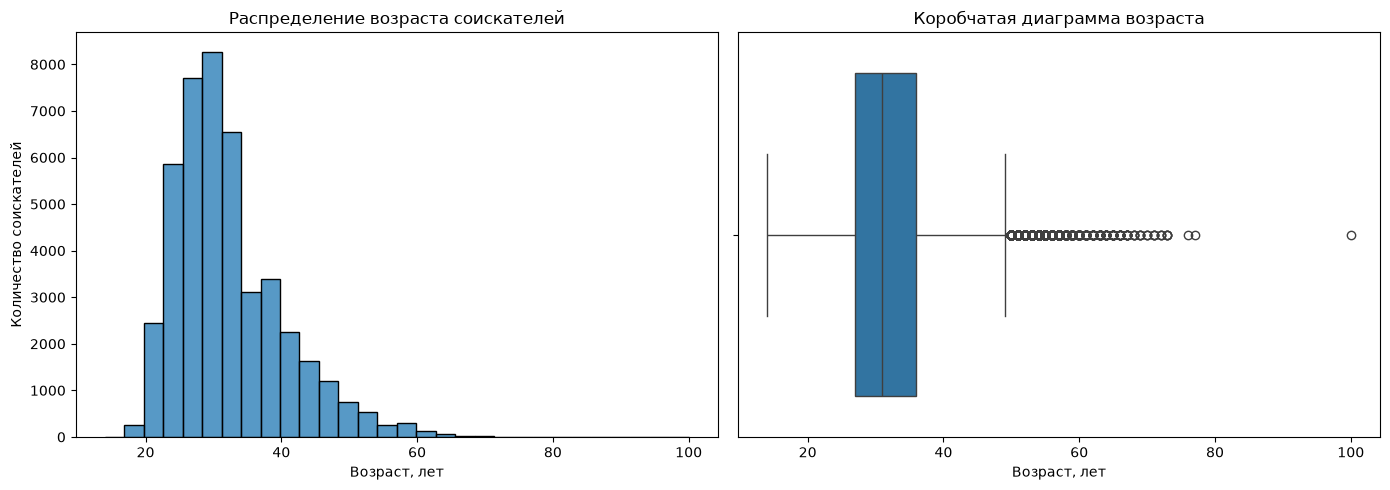

In [20]:
# Распределим возраст
age = hh_data['Возраст']

# Основные статистические показатели
mode_age = age.mode()[0]
min_age = age.min()
max_age = age.max()
q1 = age.quantile(0.25)
q3 = age.quantile(0.75)

# Статистические выбросы
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

anomalies = age[(age < lower_bound) | (age > upper_bound)]

print(f'Мода распределения: {mode_age} лет')
print(f'Минимальный возраст: {min_age} лет')
print(f'Максимальный возраст: {max_age} лет')
print(f'Возрастной интервал для 90% соискателей: {age.quantile(0.05):.0f}–{age.quantile(0.95):.0f} лет')
print(f'Границы статистических выбросов: до {lower_bound:.1f} и выше {upper_bound:.1f} лет')
print(f'Количество статистических выбросов: {len(anomalies)}')

# Построим графики
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(age, bins=30, ax=axes[0])
axes[0].set_title('Распределение возраста соискателей')
axes[0].set_xlabel('Возраст, лет')
axes[0].set_ylabel('Количество соискателей')

sns.boxplot(x=age, ax=axes[1])
axes[1].set_title('Коробчатая диаграмма возраста')
axes[1].set_xlabel('Возраст, лет')

plt.tight_layout()
plt.show()

ВЫВОД: Возраст большинства соискателей в диапазоне 22–48 лет, наиболее часто встречающийся возраст - 30 лет. График показывает, что с увеличением возраста количество соискателей постепенно снижается. Выявленные выбросы (1 774 наблюдения) преимущественно связаны с возрастом старше 49 лет. 

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

In [21]:
experience = hh_data['Опыт работы (месяц)'].dropna()

# Статистические показатели
mode = experience.mode()
q1 = experience.quantile(0.25)
q3 = experience.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print('Мода распределения:', mode.tolist())
print('Минимальный опыт:', experience.min())
print('Максимальный опыт:', experience.max())
print('Интервал для 90% соискателей:',
      experience.quantile(0.05),
      '-',
      experience.quantile(0.95))
print('Границы статистических выбросов:',
      lower_bound, 'и', upper_bound)
print('Количество статистических выбросов:',
      ((experience < lower_bound) | (experience > upper_bound)).sum())

# Гистограмма и коробчатая диаграмма
fig = px.histogram(
    x=experience,
    marginal='box',
    title='Распределение опыта работы соискателей',
    labels={'x': 'Опыт работы, месяцев'}
)

# Настройка оси Y и всплывающей подсказки
fig.update_yaxes(title_text='Количество соискателей', row=1, col=1)
fig.data[0].hovertemplate = 'Опыт работы, месяцев: %{x}<br>Количество соискателей: %{y}<extra></extra>'

fig.write_html('Графики/experience_distribution.html')
fig.show()

Мода распределения: [81.0]
Минимальный опыт: 1.0
Максимальный опыт: 1188.0
Интервал для 90% соискателей: 16.0 - 264.0
Границы статистических выбросов: -88.5 и 299.5
Количество статистических выбросов: 1276


ВЫВОД: Чаще всего соискатели имеют опыт около 81 месяца (почти 7 лет). У большинства стаж составляет от 16 до 264 месяцев. Обнаружено 1276 статистических выбросов. Максимальный стаж - 1188 месяцев (99 лет), что, вероятно, указывает на ошибку в данных.

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


In [22]:
salary = hh_data['ЗП (руб)'].dropna()

# Статистические показатели
mode = salary.mode()
q1 = salary.quantile(0.25)
q3 = salary.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print('Мода распределения:', mode.tolist())
print('Минимальная зарплата:', salary.min())
print('Максимальная зарплата:', salary.max())
print('Интервал для 90% соискателей:',
      salary.quantile(0.05), '-',
      salary.quantile(0.95))
print('Границы статистических выбросов:',
      lower_bound, 'и', upper_bound)
print('Количество статистических выбросов:',
      ((salary < lower_bound) | (salary > upper_bound)).sum())

# Гистограмма и коробчатая диаграмма
fig = px.histogram(
    x=salary,
    marginal='box',
    title='Распределение желаемой заработной платы',
    labels={'x': 'Желаемая зарплата, руб.'}
)

# Настройка осей и всплывающей подсказки
fig.update_xaxes(range=[0, 200000])
fig.update_yaxes(title_text='Количество соискателей', row=1, col=1)
fig.data[0].hovertemplate = 'Желаемая зарплата, руб.: %{x}<br>Количество соискателей: %{y}<extra></extra>'

fig.write_html('Графики/salary_distribution.html')
fig.show()


Мода распределения: [50000.0]
Минимальная зарплата: 1.0
Максимальная зарплата: 24304876.0
Интервал для 90% соискателей: 20000.0 - 200000.0
Границы статистических выбросов: -49794.500000000015 и 181876.7
Количество статистических выбросов: 2781


ВЫВОД: Ожидания большинства соискателей сосредоточены в пределах 20-200 тыс. рублей, чаще всего встречается значение 50 тыс. рублей. По диаграмме видно, что распределение заработной платы имеет длинный правый хвост - некоторые соискатели указывают значительно более высокие суммы. Максимальное значение - 24,3 млн рублей, а минимальное - всего 1 рубль.

4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

In [23]:
# Исключим влияние выбросов
salary_education = hh_data[hh_data['ЗП (руб)'] < 1000000]

# Cруппируем данные по уровню образования и вычислим медианную
median_salary = salary_education.groupby('Образование')['ЗП (руб)'].median().reset_index()

# Cруппируем данные по уровню образования и вычислим медианную
median_salary = median_salary.sort_values('ЗП (руб)')

# Горизонтальная столбчатая диаграмма
fig = px.bar(
    median_salary,
    x='ЗП (руб)',
    y='Образование',
    orientation='h',
    title='Медианная желаемая зарплата в зависимости от образования',
    labels={'ЗП (руб)': 'Медианная зарплата, руб.', 'Образование': 'Уровень образования'}
)

fig.write_html('Графики/salary_education_distribution.html')
fig.show()

ВЫВОД: По графику видно, что самая высокая медианная зарплата у соискателей с высшим образованием - 60 000 рублей, самая низкая - у соискателей со средним и средним специальным образованием - около 40 000 рублей. Чем выше уровень образования, тем выше желаемая зарплата.

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

In [24]:
salary_city = hh_data[hh_data['ЗП (руб)'] < 1000000]

# Построим коробчатую диаграмму
fig = px.box(
    salary_city,
    x='Город',
    y='ЗП (руб)',
    title='Распределение желаемой зарплаты по городам',
    labels={'Город': 'Город', 'ЗП (руб)': 'Желаемая зарплата, руб.'}
)

# Отсортируем категории городов по оси X по убыванию медианной зарплаты
fig.update_xaxes(categoryorder='median descending')

fig.write_html('Графики/salary_city_distribution.html')
fig.show()

ВЫВОД: Город влияет на уровень зарплатных ожиданий: в Москве и Санкт-Петербурге они выше, поэтому признак важен для прогнозирования зарплаты. В Москве медианная зарплата самая высокая - около 85 тыс. рублей, в Санкт-Петербурге примерно 60 тыс., а в городах-миллионниках и остальных городах около 40 тыс. рублей.

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

In [25]:
# Резюме, в которых желаемая зарплата меньше 1 млн рублей
salary_ready = hh_data[hh_data['ЗП (руб)'] < 1000000]

# Сгруппируем данные по готовности к переезду и командировкам
# Для каждой группы рассчитаем медианную желаемую зарплату
grouped_salary = salary_ready.groupby(
    ['Готовность к переезду', 'Готовность к командировкам'],
    as_index=False
)['ЗП (руб)'].median()

# Многоуровневая столбчатая диаграмма
fig = px.bar(
    grouped_salary,
    x='Готовность к переезду',
    y='ЗП (руб)',
    color='Готовность к командировкам',
    barmode='group',
    title='Медианная зарплата в зависимости от готовности к переезду и командировкам',
    labels={
        'ЗП (руб)': 'Медианная зарплата, руб.',
        'Готовность к переезду': 'Готовность к переезду',
        'Готовность к командировкам': 'Готовность к командировкам'
    }
)

fig.write_html('Графики/salary_ready_distribution.html')
fig.show()

ВЫВОД: Оба признака связаны с зарплатными ожиданиями. Среди соискателей, готовых к командировкам, медианная зарплата составляет около 60-65 тысяч рублей, среди неготовых - 40-50 тысяч рублей. Самые высокие ожидания у тех, кто готов и к переезду, и к командировкам (около 66 тысяч рублей).

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

In [26]:
# Сгруппируем возраст соискателей с шагом 5 лет
age_bins = [13, 19, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 74, 79]

age_labels = [
    '14-19', '20-24', '25-29', '30-34',
    '35-39', '40-44', '45-49', '50-54',
    '55-59', '60-64', '65-69', '70-74', '75-79'
]

# Создаём отдельную серию с возрастными группами, не изменяя основной датафрейм hh_data
age_groups = pd.cut(
    hh_data['Возраст'],
    bins=age_bins,
    labels=age_labels
)

# Проверяем возраст, не попавший в интервалы
print('Возраст вне заданных интервалов:')
print(hh_data.loc[age_groups.isna(), 'Возраст'].unique())

# Строим сводную таблицу
pivot_age = hh_data.pivot_table(
    values='ЗП (руб)',
    index=age_groups,
    columns='Образование',
    aggfunc='median'
)

# Выводим сводную таблицу
pivot_age


Возраст вне заданных интервалов:
[100]


Образование,высшее,неоконченное высшее,среднее,среднее специальное
Возраст,,,,
14-19,30000.000,26000.0,40000.0,29000.0
20-24,45000.000,40000.0,40000.0,30000.0
25-29,55000.000,50000.0,40000.0,40000.0
30-34,67500.000,55000.0,45000.0,40000.0
35-39,76573.975,60000.0,50000.0,41500.0
40-44,80000.000,75000.0,45000.0,45000.0
45-49,80000.000,70000.0,45000.0,40000.0
50-54,70000.000,50000.0,40000.0,40000.0
55-59,66666.000,55000.0,30000.0,42438.0


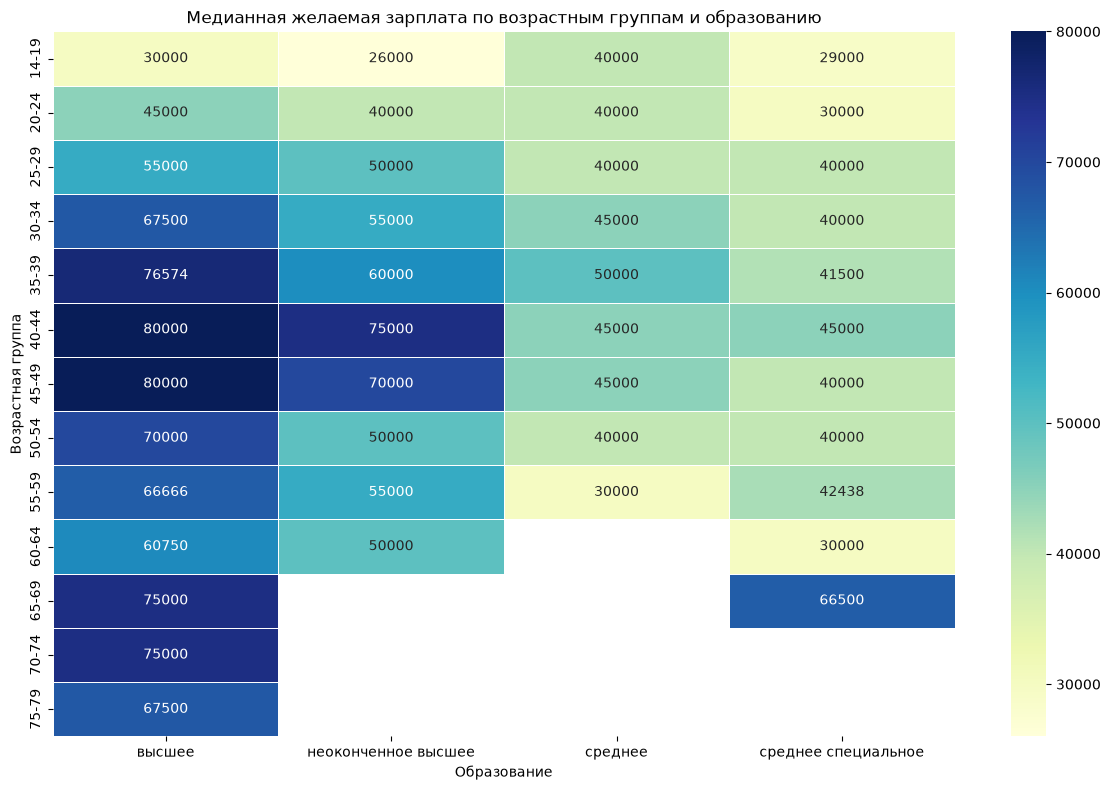

In [27]:
# Построим тепловую карту
plt.figure(figsize=(12, 8))

sns.heatmap(
    data=pivot_age,
    cmap='YlGnBu',
    annot=True,
    fmt='.0f',
    linewidths=0.5
)

plt.title('Медианная желаемая зарплата по возрастным группам и образованию')
plt.xlabel('Образование')
plt.ylabel('Возрастная группа')

plt.tight_layout()
plt.show()

ВЫВОД: В результате анализа видно, что наиболее высокие зарплатные ожидания характерны для соискателей с высшим образованием в возрасте 40-49 лет и достигают 80 000 рублей.Соискатели с высшим образованием рассчитывают на более высокую оплату труда, чем соискатели со средним и средним специальным образованием. После 50 лет медианная зарплата преимущественно снижается.

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

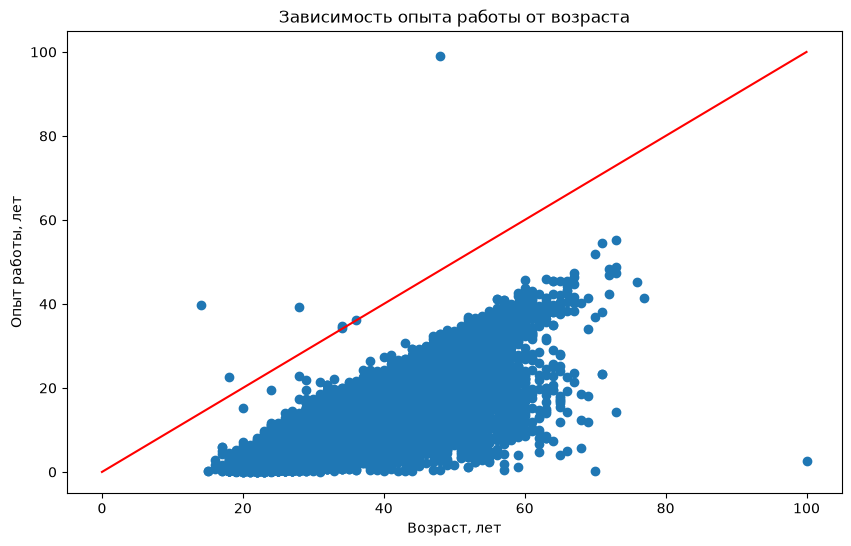

In [28]:
# Переведем опыт работы из месяцев в годы
experience_years = hh_data['Опыт работы (месяц)'] / 12

# Построим диаграмму рассеяния
plt.figure(figsize=(10, 6))

plt.scatter(
    hh_data['Возраст'],
    experience_years
)

# Добавим контрольную прямую
plt.plot([0, 100], [0, 100], color='red')

plt.title('Зависимость опыта работы от возраста')
plt.xlabel('Возраст, лет')
plt.ylabel('Опыт работы, лет')

plt.show()

ВЫВОД: На диаграмме рассеяния выявлены 7 записей, в которых опыт работы превышает или равен возрасту соискателя. Во всех семи случаях стаж превышает возраст - логическое противоречие в данных. Что касается корректых данных - с увеличением возраста растёт продолжительность трудового стажа. 

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


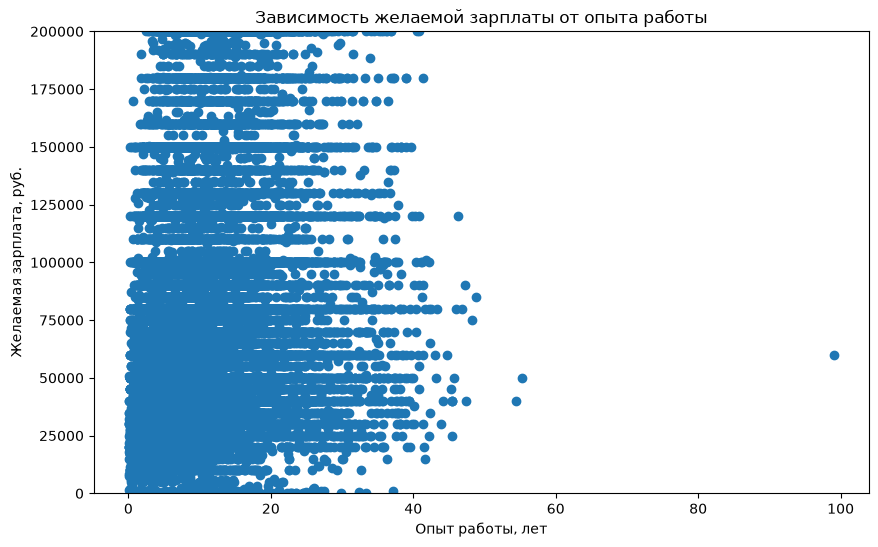

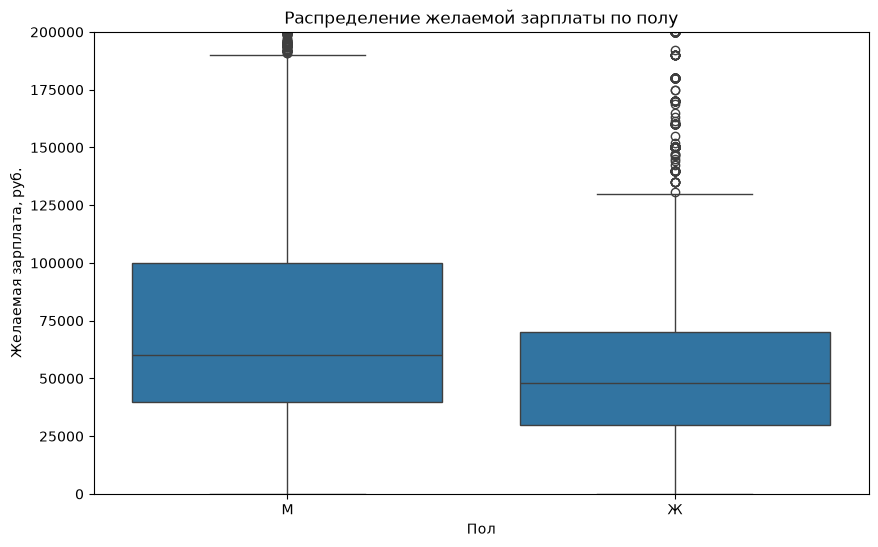

In [29]:
# Зависимость желаемой зарплаты от опыта работы
plt.figure(figsize=(10, 6))

plt.scatter(
    hh_data['Опыт работы (месяц)'] / 12,
    hh_data['ЗП (руб)']
)

plt.title('Зависимость желаемой зарплаты от опыта работы')
plt.xlabel('Опыт работы, лет')
plt.ylabel('Желаемая зарплата, руб.')
plt.ylim(0, 200000)

plt.show()


# Распределение желаемой зарплаты по полу
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=hh_data,
    x='Пол',
    y='ЗП (руб)'
)

plt.title('Распределение желаемой зарплаты по полу')
plt.xlabel('Пол')
plt.ylabel('Желаемая зарплата, руб.')
plt.ylim(0, 200000)

plt.show()

ВЫВОД: Между опытом работы и желаемой зарплатой не наблюдается выраженной зависимости. Высокие зарплатные ожидания встречаются как с небольшим, так и с большим опытом работы. Мужчины указывают более высокую желаемую зарплату: медиана составляет около 60 000 рублей против 48 000 рублей у женщин. Разброс зарплатных ожиданий у мужчин выше чем у женщин.

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [30]:
hh_data.duplicated().sum()

np.int64(161)

In [31]:
hh_data = hh_data.drop_duplicates()

2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [32]:
hh_data.isna().sum()

Ищет работу на должность:            0
Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Обновление резюме                    0
Авто                                 0
Образование                          0
Пол                                  0
Возраст                              0
Опыт работы (месяц)                168
Город                                0
Готовность к переезду                0
Готовность к командировкам           0
Занятость — полная                   0
Занятость — частичная                0
Занятость — проектная                0
Занятость — стажировка               0
Занятость — волонтерство             0
График — полный день                 0
График — сменный                     0
График — гибкий                      0
График — удаленная работа            0
График — вахтовый                    0
ЗП (руб)                             0
dtype: int64

3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [33]:
# Удалим строки с пропусками в столбцах с последним местом работы и должностью
hh_data = hh_data.dropna(
    subset=['Последнее/нынешнее место работы', 'Последняя/нынешняя должность']
)

# Заполним пропуски в столбце с опытом работы медианным значением
hh_data['Опыт работы (месяц)'] = hh_data['Опыт работы (месяц)'].fillna(
    hh_data['Опыт работы (месяц)'].median()
)

hh_data.isna().sum()

Ищет работу на должность:          0
Последнее/нынешнее место работы    0
Последняя/нынешняя должность       0
Обновление резюме                  0
Авто                               0
Образование                        0
Пол                                0
Возраст                            0
Опыт работы (месяц)                0
Город                              0
Готовность к переезду              0
Готовность к командировкам         0
Занятость — полная                 0
Занятость — частичная              0
Занятость — проектная              0
Занятость — стажировка             0
Занятость — волонтерство           0
График — полный день               0
График — сменный                   0
График — гибкий                    0
График — удаленная работа          0
График — вахтовый                  0
ЗП (руб)                           0
dtype: int64

4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [34]:
# Найдем выбросы
outliers_salary = hh_data[(hh_data['ЗП (руб)'] > 1e6) | (hh_data['ЗП (руб)'] < 1e3)]

# Удалим найденные выбросы 
hh_data = hh_data.drop(outliers_salary.index)

outliers_salary.shape[0], hh_data.shape

(89, (44492, 23))

5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [35]:
# Найдем выбросы
outliers_exp = hh_data[hh_data['Опыт работы (месяц)'] / 12 > hh_data['Возраст']]

# Удаляем найденные выбросы
hh_data = hh_data.drop(outliers_exp.index)

outliers_exp.shape[0], hh_data.shape

(7, (44485, 23))

6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

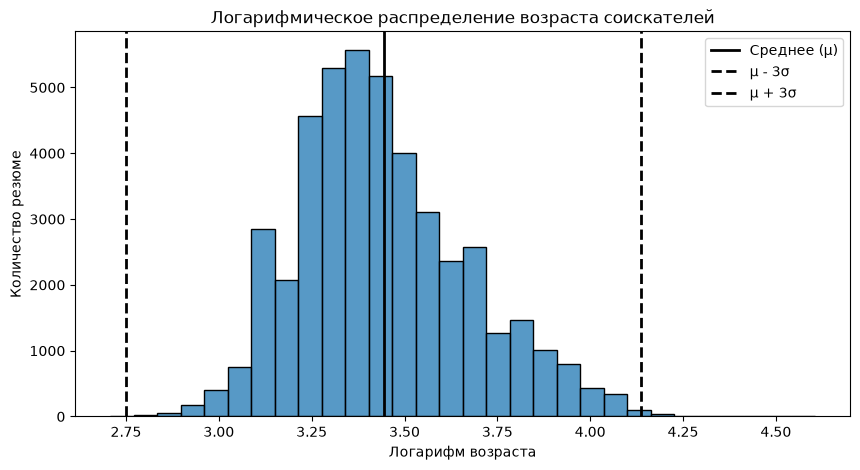

,Ищет работу на должность:,Последнее/нынешнее место работы,Последняя/нынешняя должность,Обновление резюме,Авто,Образование,Пол,Возраст,Опыт работы (месяц),Город,...,Занятость — частичная,Занятость — проектная,Занятость — стажировка,Занятость — волонтерство,График — полный день,График — сменный,График — гибкий,График — удаленная работа,График — вахтовый,ЗП (руб)
31137,Менеджер по работе с клиентами,"ООО ""ФёрстКэшКомпани""",Менеджер по работе с клиентами,2019-04-06,Не указано,среднее,М,15,2.0,Санкт-Петербург,...,True,False,False,False,False,True,True,True,False,10000.0
32950,Тестировщик игр,OOO ЖМЫХ,Тестировщик ПО,2019-04-09,Не указано,среднее специальное,М,15,3.0,другие,...,False,False,False,False,True,False,False,False,False,2000.0
33654,Frontend-разработчик,Freelance,Frontend-разработчик,2019-04-19,Не указано,среднее специальное,М,100,30.0,Санкт-Петербург,...,True,True,True,False,True,False,True,True,False,60000.0


(44482, 23)

In [36]:
# Переведем признак 'Возраст' в логарифмический масштаб
log_age = np.log(hh_data['Возраст'])

# Вычислим среднее и стандартное отклонение 
mu = log_age.mean()
sigma = log_age.std()

# Зададим границы метода трёх сигм
lower_bound = mu - 3 * sigma
upper_bound = mu + 3 * sigma

# Построим гистограмму распределения 
fig, ax = plt.subplots(figsize=(10, 5))
histplot = sns.histplot(log_age, bins=30, ax=ax)

# Добавим вертикальные линии среднего и границ трёх сигм
histplot.axvline(mu, color='k', lw=2, label='Среднее (μ)')
histplot.axvline(lower_bound, color='k', ls='--', lw=2, label='μ - 3σ')
histplot.axvline(upper_bound, color='k', ls='--', lw=2, label='μ + 3σ')

histplot.set_title('Логарифмическое распределение возраста соискателей')
histplot.set_xlabel('Логарифм возраста')
histplot.set_ylabel('Количество резюме')
histplot.legend()
plt.show()

# Функция поиска выбросов 
def outliers_z_score_mod(data, feature, left=3, right=3, log_scale=False):
    if log_scale:
        x = np.log(data[feature])
    else:
        x = data[feature]
    mu = x.mean()
    sigma = x.std()
    lower_bound = mu - left * sigma
    upper_bound = mu + right * sigma
    outliers = data[(x < lower_bound) | (x > upper_bound)]
    cleaned = data[(x >= lower_bound) & (x <= upper_bound)]
    return outliers, cleaned

# Найдем выбросы и очистим данные 
outliers_age, hh_data = outliers_z_score_mod(
    hh_data, 'Возраст', left=3, right=4, log_scale=True
)

display(outliers_age)
hh_data.shape

ВЫВОД: Основная масса соискателей находится в диапазоне 25-45 лет. При использовании метода z-отклонений под категорию выбросов попадают 3 резюме соискателей (15 и 100 лет), скорее всего это ошибка или некорректное заполнение анкеты.